# Chapitre 12 - Exercices 12.1 à 12.5

Ce notebook traite les cinq premiers exercices du chapitre 12, centrés sur
l'intégration de données et la lecture de l'état dérivé :

- **12.1** : combien de clés divergent par jour avec la double écriture ? (calcul et
  simulation) ;
- **12.2** : quand l'ordre total sature, et ce que coûte la causalité explicite (calcul) ;
- **12.3** : bascule progressive ou bascule d'un coup : combien de lectures fausses ?
  (calcul et simulation) ;
- **12.4** : rejouer deux ans d'historique dans un nouveau consommateur (dimensionnement) ;
- **12.5** : taille optimale d'un cache de requêtes fréquentes sous une loi de Zipf
  (calcul et mini-lab).

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 12.1 : combien de clés divergent par jour avec la double écriture ?

**Énoncé.** Une application écrit elle-même chaque mise à jour dans sa base **et** dans
son index de recherche (double écriture). Chaque envoi subit un délai réseau égal à une
constante plus une variable exponentielle de moyenne $j = 20$ ms, indépendante pour
chaque message. Chaque système garde la dernière valeur reçue.

1. Deux clients modifient la même clé, le second $g$ millisecondes après le premier.
   Montrer que, dans un système donné, la première écriture arrive après la seconde avec
   probabilité $p(g) = \frac12 e^{-g/j}$, et que base et index divergent avec probabilité
   $2p(1-p)$.
2. Chaque jour, 50 000 paires d'écritures concurrentes sur une même clé se produisent,
   avec un écart $g$ uniforme entre 0 et 50 ms. Combien de clés divergent par jour ?
3. Vérifier par simulation.
4. Pourquoi un horodatage attaché par le client à chaque écriture (on garde la plus
   récente) ne règle-t-il pas complètement le problème ?

**Rappels.** Sans journal unique, chaque système applique les écritures dans l'ordre où
il les reçoit ; un journal ordonné décide une fois pour toutes (cours 1, section 2 ;
section *Reasoning about dataflows*).

**Solution.**

*1.* Notons $D_A, D_B$ les délais exponentiels (la constante s'annule). A arrive après B
si $D_A > g + D_B$, soit $X = D_A - D_B > g$. La différence de deux exponentielles
indépendantes de même paramètre suit une loi de Laplace de densité $\frac{1}{2j}e^{-|x|/j}$,
donc pour $g \ge 0$ : $P(X > g) = \int_g^\infty \frac{1}{2j} e^{-x/j}\,dx = \frac12 e^{-g/j}$.
Les deux systèmes sont indépendants : ils divergent si l'un garde A et l'autre B, soit
$p(1-p) + (1-p)p = 2p(1-p)$.

*2.* $2p - 2p^2 = e^{-g/j} - \frac12 e^{-2g/j}$. En moyenne sur $g$ uniforme dans $[0, G]$ :

$$\overline{P} = \frac{j}{G}\left(1 - e^{-G/j}\right) - \frac{j}{4G}\left(1 - e^{-2G/j}\right)
= 0{,}4 \times 0{,}918 - 0{,}1 \times 0{,}993 \approx 0{,}268.$$

Plus d'un quart des paires concurrentes divergent : environ **13 400 clés par jour**,
définitivement incohérentes entre la base et l'index.

*4.* Avec un horodatage client et la règle « la plus récente gagne », les deux systèmes
convergent vers la **même** valeur (ils appliquent la même règle aux mêmes données). Mais
cette valeur dépend d'horloges non synchronisées (chapitre 8) : si l'horloge
du client A avance de 30 ms, son écriture « gagne » alors qu'elle est antérieure, et
l'écriture de B est **perdue silencieusement** dans les deux systèmes. On remplace une
divergence par une perte de mise à jour. Le journal unique donne au contraire un ordre
que tous les consommateurs partagent.

**Vérification** : formule, intégrale numérique et simulation (`dfl.dual_write_divergence`).

formule 0.2678 ; intégrale numérique 0.2679 ; simulation 0.2682
clés divergentes par jour : 13 392


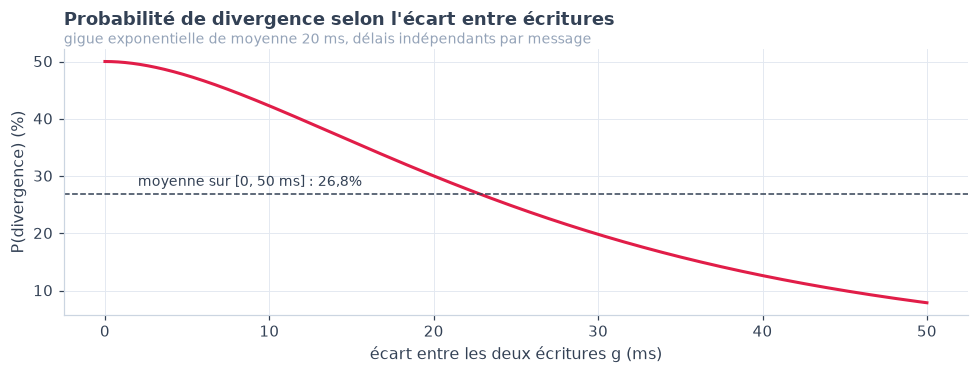

In [2]:
G, j = 50.0, 20.0
moy = (j / G) * (1 - math.exp(-G / j)) - (j / (4 * G)) * (1 - math.exp(-2 * G / j))
gs = np.linspace(0, G, 2001)
integ = np.mean([dfl.dual_write_divergence_formula(g, j) for g in gs])
rng = np.random.default_rng(0)
sim = np.mean([dfl.dual_write_divergence(g, j, n_trials=200, seed=i) for i, g in enumerate(rng.uniform(0, G, 2500))])
print(f"formule {moy:.4f} ; intégrale numérique {integ:.4f} ; simulation {sim:.4f}")
print(f"clés divergentes par jour : {fmt(50_000 * moy)}")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(gs, [dfl.dual_write_divergence_formula(g, j) * 100 for g in gs], color=ROSE)
ax.axhline(moy * 100, color=SLATE, ls="--", lw=1)
ax.text(2, moy * 100 + 1.5, f"moyenne sur [0, 50 ms] : {moy:.1%}".replace(".", ","), color=SLATE, fontsize=9)
ax.set_xlabel("écart entre les deux écritures g (ms)"); ax.set_ylabel("P(divergence) (%)")
ax.set_title("Probabilité de divergence selon l'écart entre écritures")
subtitle(ax, "gigue exponentielle de moyenne 20 ms, délais indépendants par message")
plt.tight_layout(); plt.show()

Formule, intégrale et simulation concordent à 27 % : la double écriture produit chaque
jour plus de dix mille incohérences permanentes dans ce scénario modeste.

> **À retenir.** Pour des délais exponentiels, la divergence vaut $2p(1-p)$ avec
> $p = \frac12 e^{-g/j}$ : elle n'est négligeable que si les écritures concurrentes sont
> espacées de plusieurs fois la gigue. Un horodatage client fait converger mais perd des
> écritures ; seul un ordre unique (journal) règle le problème.

## Exercice 12.2 : quand l'ordre total sature, et ce que coûte la causalité explicite

**Énoncé.** Un journal à leader unique ordonne tous les événements d'une plateforme.

1. Le leader supporte au plus 200 000 événements/s. La charge actuelle est de 120 000
   événements/s et croît de 60 % par an. Dans combien de temps faut-il
   partitionner le journal ?
2. Après partitionnement, les amitiés et les messages sont dans des journaux différents.
   Le service de notifications les reçoit avec des délais indépendants, exponentiels de
   moyenne 1 s. Un utilisateur retire un ami puis, 0,5 s plus tard, envoie un message
   désobligeant. Quelle est la probabilité que l'ex-ami soit notifié ?
3. Correctif : le message porte la version de la liste d'amis vue par l'expéditeur, et
   le service attend de l'avoir appliquée. Calculer l'attente moyenne ajoutée.
4. Pourquoi les horodatages de Lamport ne suffisent-ils pas, seuls, à éviter la fuite ?

**Rappels.** L'ordre total équivaut au consensus et passe par un nœud ; sans lui, les
dépendances causales entre journaux se perdent (cours 1, sections 4 et 5 ; sections
*The limits of total ordering* et *Ordering events to capture causality*).

**Solution.**

*1.* $120\,000 \times 1{,}6^t = 200\,000 \iff t = \ln(5/3) / \ln 1{,}6 \approx 1{,}09$ an :
un peu plus d'un an, en supposant une croissance régulière (les pics saisonniers
avanceront l'échéance).

*2.* Avec $X = D_f - D_m$ (délai du retrait moins délai du message), la fuite a lieu si le
retrait arrive après le message : $X > g$, de probabilité $\frac12 e^{-g/j} =
\frac12 e^{-0{,}5} \approx 30{,}3$ %.

*3.* L'attente vaut $(X - g)^+$. Pour la loi de Laplace,
$E[(X-g)^+] = \int_g^\infty (x-g)\frac{1}{2j}e^{-x/j}dx = \frac{j}{2}e^{-g/j} \approx 0{,}303$ s.
Remarquable : l'attente moyenne est numériquement égale à la probabilité de fuite (en
unités de $j$), car quand il faut attendre, l'attente résiduelle est exponentielle de
moyenne $j$ (absence de mémoire).

*4.* Un horodatage de Lamport donne un ordre total cohérent avec la causalité, mais le
service ne sait pas, à la réception du message (horodatage 12, disons), s'il existe
encore un événement d'horodatage plus petit en route : il devrait attendre d'avoir reçu
quelque chose de plus récent de **chaque** journal, ce qui revient à reconstruire un ordre
total, avec un coût de métadonnées. La référence explicite dit **exactement** quoi
attendre.

**Vérification** (`dfl.unfriend_experiment`).

In [3]:
t_sat = math.log(200 / 120) / math.log(1.6)
r = dfl.unfriend_experiment([0.5], jitter=1.0, n_trials=200_000, seed=1)
pd.DataFrame({"grandeur": ["saturation du leader (années)", "P(fuite) sans correctif", "attente moyenne avec correctif (s)",
                           "attente p99 avec correctif (s)"],
              "calcul": [f"{t_sat:.3f}", f"{0.5 * math.exp(-0.5):.4f}", f"{0.5 * math.exp(-0.5):.4f}", "-"],
              "simulation": ["-", f"{r['leak'][0]:.4f}", f"{r['wait_mean'][0]:.4f}", f"{r['wait_p99'][0]:.2f}"]})

,grandeur,calcul,simulation
0,saturation du leader (années),1.087,-
1,P(fuite) sans correctif,0.3033,0.3033
2,attente moyenne avec correctif (s),0.3033,0.3030
3,attente p99 avec correctif (s),-,3.41


La simulation retrouve 30 % de fuites et 0,30 s d'attente moyenne. Le p99 de l'attente
(près de 3,4 s) rappelle que le correctif ajoute parfois une latence notable : c'est le
prix de la causalité.

> **À retenir.** Un leader unique finit toujours par saturer ; après découpage, une
> dépendance causale entre journaux fuit avec probabilité $\frac12 e^{-g/j}$. La rendre
> explicite coûte en moyenne $\frac{j}{2}e^{-g/j}$ d'attente, avec une queue de l'ordre de
> quelques $j$.